# 08 — Splines, tail-aware mixtures, Tweedie loss and rebalance features

Checkpoint 5 explores four alternatives developed around the **earlier verified 58-feature LightGBM**. Splines test smooth nonlinear effects, the mixture separates normal and spike conditions, Tweedie changes the share-loss objective, and scheduled event features add each stock's prior auction response.

The notebook reconstructs the saved spline and mixture models across 2022–2025, verifies the saved Tweedie/event forecasts and performs a fresh 2022 four-way loss/event experiment. Saved results, model reconstructions and fresh fitting are labelled separately. Applying these methods to the later tuned 61-feature champion remains an additional experiment.

The stock-level point-accuracy conclusion retains LightGBM. The event-feature log model improves its matched control. Tweedie improves daily-total volume error and bias, with higher stock-level log error. These are different objective tradeoffs, which we quantify below.

Run in the repository's project environment with the EDA/model dependencies. New verification and worked-fit artifacts are saved under `outputs/experiments/30_checkpoint5_master_audit`. The source experiments remain the numerical research record, and executed figures and tables are embedded here.

In [1]:
from pathlib import Path
import sys
import tempfile
import json
import hashlib
import importlib.metadata
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown, Image

PROJECT_ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                    if (p / "blackrock_data").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
DATA = PROJECT_ROOT / "blackrock_data"
RESULTS = PROJECT_ROOT / "outputs"
work = tempfile.TemporaryDirectory(prefix="auction-master-")
con = duckdb.connect()
con.execute("SET threads=4")
con.execute("SET memory_limit='2GB'")
con.execute("SET temp_directory=?", [work.name])
AUCTION = str(DATA / "stock_daily/auction_daily/year=*/auction_daily_*.parquet")
CRSP = str(DATA / "stock_daily/crsp_daily/year=*/crsp_daily_*.parquet")
TRADE = str(DATA / "stock_intraday/trade_checkpoints/year=*/trade_checkpoints_*.parquet")
MARKET = str(DATA / "market/market_daily.parquet")
SECTOR = str(DATA / "sector/sector_daily.parquet")
EVENTS = str(DATA / "events/event_calendar.parquet")
INDUSTRY = str(DATA / "reference/industry_history.parquet")
ANOMALIES = str(DATA / "quality/auction_source_anomalies.parquet")
def sql(query, params=None):
    return con.execute(query, params or []).df()
def saved(relative):
    return pd.read_csv(RESULTS / relative)
pd.set_option("display.max_columns", 16)
pd.set_option("display.max_rows", 35)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.figsize": (11, 4.5), "figure.dpi": 110})
display(pd.DataFrame({"package": ["duckdb", "numpy", "pandas", "matplotlib", "seaborn"],
                      "version": [importlib.metadata.version(p) for p in ["duckdb", "numpy", "pandas", "matplotlib", "seaborn"]]}))
import os
import time
import gc
import joblib
from datetime import datetime, timezone
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from notebooks.modeling_utils import fit_preprocessor, apply_preprocessor, forecast_metrics
sys.path.insert(0,str(PROJECT_ROOT/'notebooks'))
import run_spline_residual_experiment as sp
import run_tail_mixture_experiment as tm
import compare_daily_tweedie_and_rebalance as tw
warnings.filterwarnings('ignore', message='X does not have valid feature names')
S=RESULTS/'experiments/21_spline_residual'
T=RESULTS/'experiments/22_tail_mixture'
W=RESULTS/'experiments/23_tweedie_and_rebalance'
V=RESULTS/'reproduction/03_compact_nonlinear'
RUN=RESULTS/'experiments/30_checkpoint5_master_audit'
for directory in [RUN,RUN/'predictions',RUN/'fresh_tweedie_2022']:
    directory.mkdir(parents=True,exist_ok=True)
YEARS=[2022,2023,2024,2025];DEV=[2022,2023,2024]
LGBM='lgbm_residual_58_l2'
RIDGE='rolling5_residual_auction_calendar_liquidity'
MODELS=[sp.POOLED,sp.HIERARCHICAL,tm.LOG_MIX,tm.SHARE_MIX,LGBM]
LABELS={sp.POOLED:'Pooled spline',sp.HIERARCHICAL:'Spline + stock effect',tm.LOG_MIX:'Tail mixture, log mean',
        tm.SHARE_MIX:'Tail mixture, share mean',LGBM:'Verified 58-feature LightGBM'}
PANEL=next(p for p in [RESULTS/'eda/05_feature_engineering/enriched_daily_panel.parquet',
    PROJECT_ROOT/'midterm presentation/data_analysis/cache/enriched_daily_panel.parquet',
    RESULTS/'experiments/21_ridge_target_definitions/daily_panel.parquet'] if p.is_file())
def read(folder,name):return pd.read_csv(folder/name)
def progress(message):
    line=f'{datetime.now(timezone.utc).isoformat()} {message}'
    print(line,flush=True)
    with (RUN/'progress.log').open('a') as handle:handle.write(line+'\n')
def write_json(path,value):
    temporary=path.with_suffix(path.suffix+'.partial');temporary.write_text(json.dumps(value,indent=2));temporary.replace(path)
def write_frame(frame,path):
    temporary=path.with_suffix('.partial');temporary.unlink(missing_ok=True)
    con.register('checkpoint5_output',frame)
    try:con.execute('COPY checkpoint5_output TO ? (FORMAT PARQUET, COMPRESSION ZSTD)',[str(temporary)])
    finally:con.unregister('checkpoint5_output')
    temporary.replace(path)
def digest(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda:handle.read(8*1024*1024),b''):h.update(chunk)
    return h.hexdigest()
versions={name:importlib.metadata.version(name) for name in ['lightgbm','scikit-learn','joblib','duckdb','numpy','pandas']}
display(pd.Series(versions,name='execution version').to_frame())
plan={'version':1,'panel_hash':digest(PANEL),'versions':versions,'reconstruction_years':YEARS,
      'fresh_year':2022,'fresh_scope':'original four-way Tweedie/event comparison',
      'fresh_row_caps':[180000,100000,300000],'fresh_threads':4,
      'source_hashes':{p.name:digest(p) for p in [PROJECT_ROOT/'notebooks/run_spline_residual_experiment.py',
          PROJECT_ROOT/'notebooks/run_tail_mixture_experiment.py',PROJECT_ROOT/'notebooks/compare_daily_tweedie_and_rebalance.py']}}
PLAN_HASH=hashlib.sha256(json.dumps(plan,sort_keys=True).encode()).hexdigest()
if (RUN/'plan.json').is_file():assert json.loads((RUN/'plan.json').read_text())==plan
else:write_json(RUN/'plan.json',plan)

,package,version
0,duckdb,1.5.6
1,numpy,2.4.6
2,pandas,3.1.1
3,matplotlib,3.11.2
4,seaborn,0.13.2


,execution version
lightgbm,4.6.0
scikit-learn,1.9.1
joblib,1.6.0
duckdb,1.5.6
numpy,2.4.6
pandas,3.1.1


## Shared target, references and error objectives

The spline and mixture models learn $r_t=\log(1+A_t)-\log(1+M_{20,t})$, using information available at the preceding close. They tune on Y−6 through Y−2, validate on Y−1, and refit on Y−5 through Y−1 for evaluation year Y. The Tweedie experiment uses the same chronology with a raw-share objective and an initial forecast anchored to the same historical median.

| Study | Sources | Tuning / validation / refit caps | Reference |
| --- | --- | --- | --- |
| Splines | Compact 58 | 250k / 120k / 350k | Verified 58-feature L2 LightGBM |
| Tail mixture | Compact 58 | 250k / 120k / 350k | Verified 58-feature L2 LightGBM |
| Tweedie and event features | Compact 58, optionally four event sources | 180k / 100k / 300k | Fresh matched log-loss controls plus published LightGBM |

Missing covariates, categories, transformations and scale parameters use historical fitting data. Forecast bounds use historical 0.1%/99.9% auction quantiles. Development metrics average the annual 2022–2024 values equally. The previously inspected 2025 period is confirmation evidence.

**Stock-level WAPE** is $\sum_{d,i}|\hat A_{di}-A_{di}|/\sum_{d,i}A_{di}$. **Daily-total WAPE** is $\sum_d|\sum_i\hat A_{di}-\sum_i A_{di}|/\sum_{d,i}A_{di}$. Errors can cancel between stocks in the latter measure. On the same sample, daily-total WAPE is at most stock-level WAPE. Log RMSE measures proportional accuracy and signed aggregate bias measures total-share over- or underprediction.

## Penalised cubic splines and stock-specific residual effects

The pooled model is additive in smooth functions of transformed continuous covariates:

$$\hat r_i=\alpha+\sum_j g_j(x_{ij})+z_i^\top\gamma.$$

Each $g_j$ uses cubic B-splines with quantile-spaced knots. Binary fields, missing indicators and encoded categories pass through linearly. A ridge penalty controls the expanded basis. The search tests knot counts 4, 6 and 8 and normalised penalties $10^{-5},10^{-4},10^{-3}$, with the implementation using `alpha = rows × penalty`.

After choosing the pooled specification, a second candidate adds each stock's fitting-sample mean residual with shrinkage:

$$\delta_s=\frac{n_s}{n_s+k}\bar e_s,\qquad k\in\{25,100,250\}.$$

Short histories receive a smaller correction. An unseen stock receives zero. The stock-effect candidate keeps the selected pooled spline fixed and tunes only the shrinkage constant on the same historical validation year.

n_knots  ridge_strength  \
test_year candidate                                                  
2022      spline_residual_58                     4          0.0001   
          spline_residual_58_stock_effect        4          0.0001   
2023      spline_residual_58                     8          0.0001   
          spline_residual_58_stock_effect        8          0.0001   
2024      spline_residual_58                     4          0.0001   
          spline_residual_58_stock_effect        4          0.0001   
2025      spline_residual_58                     6          0.0000   
          spline_residual_58_stock_effect        6          0.0000   

                                           stock_shrinkage  design_columns  \
test_year candidate                                                          
2022      spline_residual_58                           NaN             259   
          spline_residual_58_stock_effect         250.0000             259   
2023      spline_residual_58                           NaN             411   
          spline_residual_58_stock_effect         250.0000             411   
2024      spline_residual_58                           NaN             259   
          spline_residual_58_stock_effect         250.0000             259   
2025      spline_residual_58                           NaN             335   
          spline_residual_58_stock_effect         250.0000             335   

                                           validation_rmse_log  
test_year candidate                                             
2022      spline_residual_58                            0.5949  
          spline_residual_58_stock_effect               0.5948  
2023      spline_residual_58                            0.5300  
          spline_residual_58_stock_effect               0.5300  
2024      spline_residual_58                            0.4818  
          spline_residual_58_stock_effect               0.4816  
2025      spline_residual_58                            0.4404  
          spline_residual_58_stock_effect               0.4403

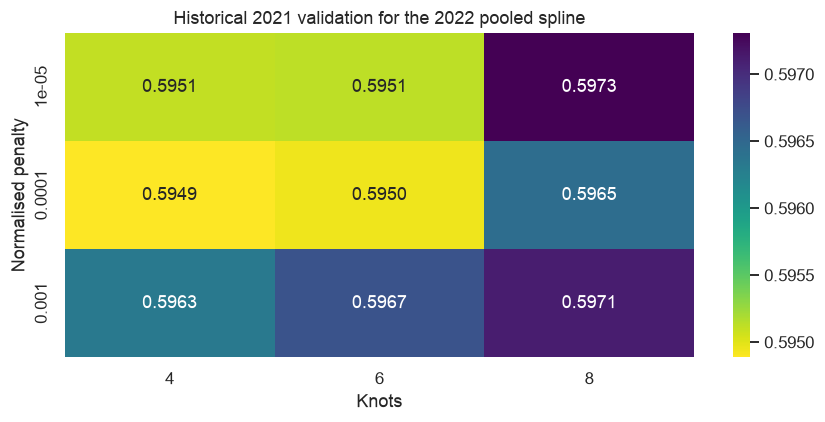

In [2]:
spline_trials=read(S,'hyperparameter_validation.csv')
spline_selected=read(S,'selected_hyperparameters.csv')
display(spline_selected[['test_year','candidate','n_knots','ridge_strength','stock_shrinkage','design_columns','validation_rmse_log']].set_index(['test_year','candidate']))
for row in spline_selected.itertuples():
    candidates=spline_trials.query('test_year == @row.test_year and candidate == @row.candidate')
    np.testing.assert_allclose(row.validation_rmse_log,candidates.validation_rmse_log.min(),atol=1e-12)
fig,ax=plt.subplots(figsize=(8,4))
table=spline_trials.query("test_year == 2022 and candidate == @sp.POOLED").pivot(index='ridge_strength',columns='n_knots',values='validation_rmse_log')
sns.heatmap(table,annot=True,fmt='.4f',cmap='viridis_r',ax=ax)
ax.set(title='Historical 2021 validation for the 2022 pooled spline',xlabel='Knots',ylabel='Normalised penalty')
plt.tight_layout();plt.show()

## Reconstruct saved models on all eligible evaluation rows

The following cell reconstructs both spline forecasts, both mixture forecasts and the verified LightGBM anchor for every year. It uses each model's saved preprocessing, feature order, historical fallback and bounds. Exact labels and date/PERMNO keys are checked against the authoritative daily benchmark. The source model scores are checked independently of the saved summary tables.

The stored spline/tail ridge-reference rows contain the earlier benchmark-summary discrepancy. We retain a reconciliation table for those rows and score the authoritative ridge forecasts separately. The primary comparisons below use the verified LightGBM anchor, whose scores can be reconstructed.

In [3]:
def model_frame(folder,year):
    prep=json.loads((folder/f'models/preprocessor_{year}.json').read_text())
    types=tuple(list(prep[k]) for k in ['continuous','boolean','categorical'])
    columns=list(dict.fromkeys(['date','permno','auction_volume','median20_auction_volume']+sum(types,[])))
    projection=', '.join(f'"{name}"' for name in columns)
    frame=sql(f"SELECT {projection} FROM read_parquet('{PANEL}') WHERE eligible_target AND year={year} ORDER BY date,permno")
    return frame,apply_preprocessor(frame,prep,*types),prep

score_rows=[];reference_rows=[];classification_rows=[]
for year in YEARS:
    path=RUN/f'predictions/reconstructed_{year}.parquet'
    progress(f'Reconstructing saved spline, mixture and LightGBM forecasts for {year}')
    frame,x,prep=model_frame(S,year)
    settings=json.loads((S/f'models/reconstruction_{year}.json').read_text())
    bundle=joblib.load(S/f'models/spline_model_{year}.joblib')
    design=sp.apply_design(x,bundle['design'])
    component=bundle['model'].predict(design)
    effects=read(S,f'models/stock_effects_{year}.csv')
    correction=sp.apply_stock_effect(frame,effects,settings['stock_selection']['stock_shrinkage'])
    base=np.log1p(frame.median20_auction_volume.fillna(settings['fallback']).to_numpy(float))
    output=frame[['date','permno','auction_volume']].copy()
    output[sp.POOLED]=np.maximum(np.expm1(np.clip(base+component,*settings['clip_log'])),0)
    output[sp.HIERARCHICAL]=np.maximum(np.expm1(np.clip(base+component+correction,*settings['clip_log'])),0)
    assert sp.apply_stock_effect(pd.DataFrame({'permno':[-999999]}),effects,250).item()==0
    del frame,x,design,bundle,effects
    gc.collect()
    frame,x,prep=model_frame(T,year)
    np.testing.assert_array_equal(frame[['date','permno','auction_volume']],output[['date','permno','auction_volume']])
    settings=json.loads((T/f'models/reconstruction_{year}.json').read_text())
    names=json.loads((T/f'models/features_{year}.json').read_text())
    matrix=x[:,[prep['output_names'].index(name) for name in names]]
    probability=lgb.Booster(model_file=str(T/f'models/spike_classifier_{year}.txt')).predict(matrix,num_threads=6)
    normal=lgb.Booster(model_file=str(T/f'models/normal_regressor_{year}.txt')).predict(matrix,num_threads=6)
    spike=lgb.Booster(model_file=str(T/f'models/spike_regressor_{year}.txt')).predict(matrix,num_threads=6)
    base=np.log1p(frame.median20_auction_volume.fillna(settings['fallback']).to_numpy(float))
    share,log,normal_log,spike_log=tm.mixture_forecasts(probability,normal,spike,base,settings['clip_log'])
    output[tm.LOG_MIX]=log;output[tm.SHARE_MIX]=share
    output['spike_probability']=probability
    output['realized_spike']=np.log1p(frame.auction_volume.to_numpy(float))-base>settings['residual_threshold']
    assert ((probability>=0)&(probability<=1)).all()
    classification_rows.append({'test_year':year,'roc_auc':roc_auc_score(output.realized_spike,probability),
        'average_precision':average_precision_score(output.realized_spike,probability),
        'brier_score':brier_score_loss(output.realized_spike,probability)})
    del frame,x,matrix
    gc.collect()
    frame,x,prep=model_frame(V,year)
    np.testing.assert_array_equal(frame[['date','permno','auction_volume']],output[['date','permno','auction_volume']])
    settings=json.loads((V/f'models/reconstruction_{year}.json').read_text())
    names=json.loads((V/f'models/feature_columns_{LGBM}_{year}.json').read_text())['output_names']
    matrix=x[:,[prep['output_names'].index(name) for name in names]]
    component=lgb.Booster(model_file=str(V/f'models/{LGBM}_{year}.txt')).predict(matrix,num_threads=6)
    base=np.log1p(frame.median20_auction_volume.fillna(settings['fallback']).to_numpy(float))
    output[LGBM]=np.maximum(np.expm1(np.clip(base+component,*settings['clip_log'])),0)
    reference_path=RESULTS/f'eda/09_global_finalists/predictions/global_finalist_predictions_{year}.parquet'
    reference=sql(f"SELECT date,permno,auction_volume,{RIDGE} FROM read_parquet('{reference_path}') ORDER BY date,permno")
    np.testing.assert_array_equal(output[['date','permno','auction_volume']],reference[['date','permno','auction_volume']])
    assert not output.duplicated(['date','permno']).any()
    ridge_score=forecast_metrics(output.auction_volume,reference[RIDGE])
    for folder in [S,T]:
        reported=read(folder,'annual_metrics.csv').query('test_year == @year and candidate == @RIDGE').iloc[0]
        reference_rows.append({'study':folder.name,'year':year,'reported_ridge_log_RMSE':reported.rmse_log,
            'authoritative_ridge_log_RMSE':ridge_score['rmse_log'],'difference':reported.rmse_log-ridge_score['rmse_log']})
    for name in MODELS:
        forecast=output[name].to_numpy(float)
        assert np.isfinite(forecast).all() and (forecast>=0).all()
        result=forecast_metrics(output.auction_volume,forecast)
        folder=V if name==LGBM else S if name.startswith('spline') else T
        source=read(folder,'nonlinear_candidate_metrics.csv' if folder==V else 'annual_metrics.csv')
        recorded=source.query('test_year == @year and candidate == @name').iloc[0]
        keys=['observations','rmse_log','wape','mae_raw','mae_log','spearman','aggregate_bias']
        np.testing.assert_allclose([result[k] for k in keys],recorded[keys].to_numpy(float),rtol=1e-9,atol=1e-10)
        score_rows.append({'year':year,'candidate':name,**result})
    write_frame(output,path)
    progress(f'{year}: verified five reconstructed forecasts on {len(output):,} common stock-days')
    del frame,x,matrix,output,reference
    gc.collect()
restored_metrics=pd.DataFrame(score_rows)
restored_metrics.to_csv(RUN/'reconstructed_metrics.csv',index=False)
reference_reconciliation=pd.DataFrame(reference_rows)
reference_reconciliation.to_csv(RUN/'ridge_reference_reconciliation.csv',index=False)
display(reference_reconciliation)
classification=pd.DataFrame(classification_rows)
recorded_classification=read(T,'classification_diagnostics.csv')
for metric in ['roc_auc','average_precision','brier_score']:
    np.testing.assert_allclose(classification[metric],recorded_classification[metric],rtol=1e-9,atol=1e-10)

2026-11-18T16:32:06.385116+00:00 Reconstructing saved spline, mixture and LightGBM forecasts for 2022


2026-11-18T16:32:32.198557+00:00 2022: verified five reconstructed forecasts on 328,634 common stock-days


2026-11-18T16:32:32.226689+00:00 Reconstructing saved spline, mixture and LightGBM forecasts for 2023


2026-11-18T16:32:56.635234+00:00 2023: verified five reconstructed forecasts on 318,679 common stock-days


2026-11-18T16:32:56.664668+00:00 Reconstructing saved spline, mixture and LightGBM forecasts for 2024


2026-11-18T16:33:20.752539+00:00 2024: verified five reconstructed forecasts on 316,212 common stock-days


2026-11-18T16:33:20.782493+00:00 Reconstructing saved spline, mixture and LightGBM forecasts for 2025


2026-11-18T16:33:38.757680+00:00 2025: verified five reconstructed forecasts on 307,853 common stock-days


,study,year,reported_ridge_log_RMSE,authoritative_ridge_log_RMSE,difference
0,21_spline_residual,2022,0.5345,0.5335,0.0010
1,22_tail_mixture,2022,0.5345,0.5335,0.0010
2,21_spline_residual,2023,0.4838,0.4837,0.0001
3,22_tail_mixture,2023,0.4838,0.4837,0.0001
4,21_spline_residual,2024,0.4454,0.4458,-0.0003
5,22_tail_mixture,2024,0.4454,0.4458,-0.0003
6,21_spline_residual,2025,0.4466,0.4451,0.0015
7,22_tail_mixture,2025,0.4466,0.4451,0.0015


## What the spline shapes and stock correction learned

The following plots vary one transformed input while holding the others fixed in the saved additive model. They show fitted response shapes, expressed as changes in the residual forecast. These are conditional model descriptions. The stock correction is shrunk toward zero according to the available fitting history.

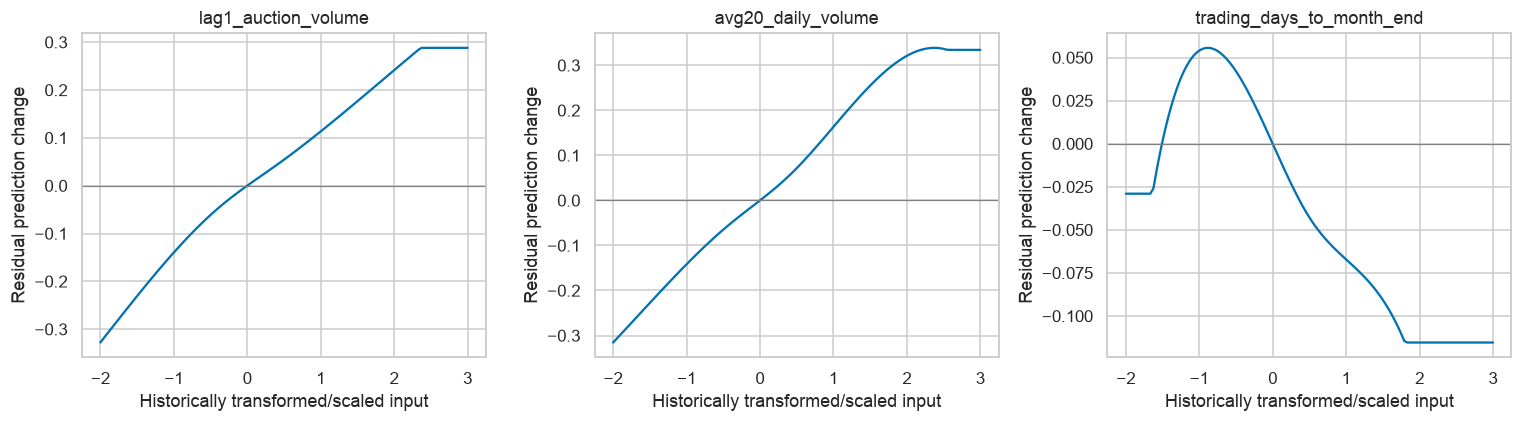

,rmse_log,wape,aggregate_bias
candidate,,,
Verified 58-feature LightGBM,0.4694,0.3545,-0.1440
Pooled spline,0.4853,0.3636,-0.1624
Spline + stock effect,0.4853,0.3633,-0.1609


,candidate,reference,period,dates,mean_log_mae_difference,ci_2_5,ci_97_5
4,spline_residual_58_stock_effect,spline_residual_58,development_2022_2024,753,-0.0000,-0.0001,0.0000
5,spline_residual_58_stock_effect,spline_residual_58,confirmation_2025,250,0.0001,0.0001,0.0002


In [4]:
prep=json.loads((S/'models/preprocessor_2022.json').read_text())
bundle=joblib.load(S/'models/spline_model_2022.joblib')
fig,axes=plt.subplots(1,3,figsize=(14,4))
for feature,ax in zip(['lag1_auction_volume','avg20_daily_volume','trading_days_to_month_end'],axes):
    index=prep['output_names'].index(feature)
    probe=np.zeros((121,len(prep['output_names'])),dtype=np.float32)
    probe[:,index]=np.linspace(-2,3,len(probe))
    effect=bundle['model'].predict(sp.apply_design(probe,bundle['design']))
    baseline=np.zeros((1,len(prep['output_names'])),dtype=np.float32)
    effect-=bundle['model'].predict(sp.apply_design(baseline,bundle['design']))[0]
    ax.plot(probe[:,index],effect)
    ax.axhline(0,color='grey',linewidth=.8)
    ax.set(title=feature,xlabel='Historically transformed/scaled input',ylabel='Residual prediction change')
plt.tight_layout();plt.show()
spline_summary=restored_metrics[restored_metrics.candidate.isin([sp.POOLED,sp.HIERARCHICAL,LGBM])]
spline_summary=(spline_summary[spline_summary.year.isin(DEV)].groupby('candidate')[['rmse_log','wape','aggregate_bias']].mean())
display(spline_summary.rename(index=LABELS))
display(read(S,'paired_date_bootstrap.csv').query('reference == @sp.POOLED'))

The pooled spline recorded development log RMSE **0.48535** and WAPE **36.36%**, compared with **0.46941** and **35.45%** for the verified LightGBM. Adding stock effects nudged log RMSE to **0.48526**, with a development paired daily log-MAE interval that included zero. The stock-specific correction supplied little incremental accuracy in this specification.

Smooth additive effects offer a different shape constraint from tree interactions. The recorded comparison favors LightGBM for point accuracy. It does not identify a unique mechanism explaining the difference between the model families.

## Tail-aware mixture

A spike is a large **median-relative log residual**, which can occur in a small or large stock. Historical validation selects a threshold at the tuning residual's 90th or 95th percentile. A binary LightGBM predicts spike probability, while two regressors estimate normal and spike residual magnitudes. The refit recomputes the chosen percentile threshold using its own historical labels.

Given probability p and component residuals z₀ and z₁, the log mixture predicts `(1−p)z₀ + p z₁` before reconstruction. The share mixture reconstructs each component and averages shares. The source implementation bounds components before the share mixture and bounds the combined residual in the log mixture. Their different bounding order is preserved here.

,tail_quantile,classifier_iterations,normal_iterations,spike_iterations,validation_log_mix_rmse
test_year,,,,,
2022,0.9500,1339,1216,541,0.5817
2023,0.9000,1500,715,666,0.5115
2024,0.9000,1130,753,769,0.4635
2025,0.9000,969,803,190,0.4378


,tail_quantile,residual_threshold,observed_spike_rate,mean_predicted_probability,roc_auc,average_precision,brier_score
test_year,,,,,,,
2022,0.9500,1.3506,0.0408,0.0436,0.9234,0.6033,0.0233
2023,0.9000,0.8709,0.0700,0.0725,0.8602,0.5817,0.0419
2024,0.9000,0.8075,0.0719,0.0679,0.8342,0.5558,0.0445
2025,0.9000,0.7561,0.0771,0.0753,0.8280,0.5229,0.0501


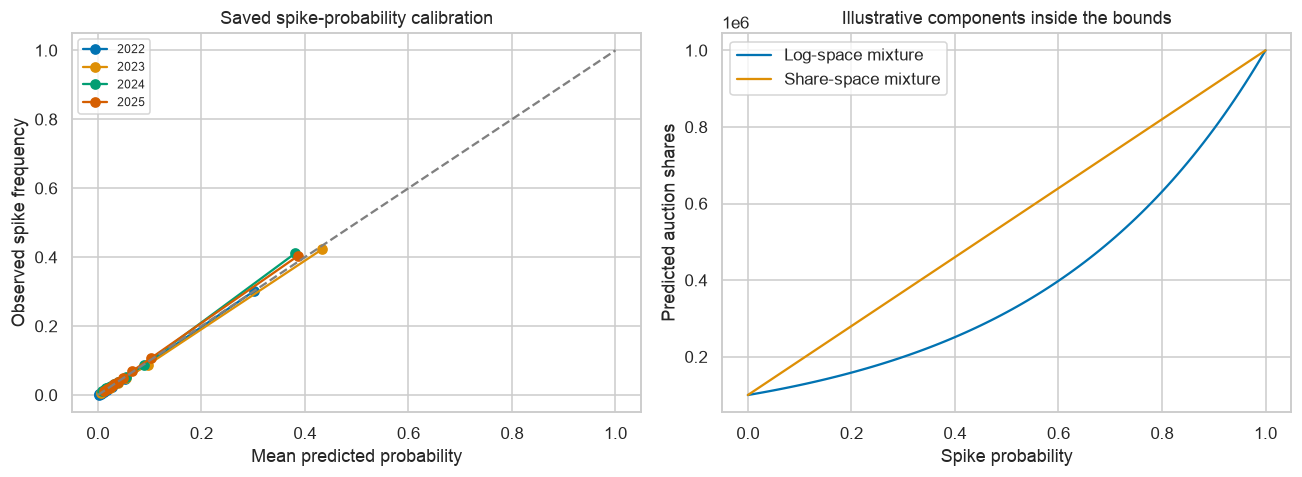

In [5]:
threshold_trials=read(T,'threshold_validation.csv')
threshold_selected=read(T,'selected_thresholds.csv')
for row in threshold_selected.itertuples():
    assert row.tail_quantile in [.9,.95]
    candidates=threshold_trials[threshold_trials.test_year.eq(row.test_year)]
    np.testing.assert_allclose(row.validation_log_mix_rmse,candidates.validation_log_mix_rmse.min(),atol=1e-12)
display(threshold_selected[['test_year','tail_quantile','classifier_iterations','normal_iterations','spike_iterations','validation_log_mix_rmse']].set_index('test_year'))
display(recorded_classification.set_index('test_year'))
calibration=read(T,'probability_calibration.csv')
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for year,group in calibration.groupby('test_year'):
    axes[0].plot(group.mean_probability,group.observed_rate,marker='o',label=str(year))
axes[0].plot([0,1],[0,1],color='grey',linestyle='--')
axes[0].set(title='Saved spike-probability calibration',xlabel='Mean predicted probability',ylabel='Observed spike frequency')
axes[0].legend(fontsize=8)
prob=np.linspace(0,1,101)
share_mix,log_mix,_,_=tm.mixture_forecasts(prob,np.zeros_like(prob),np.full_like(prob,np.log(10)),
    np.full_like(prob,np.log1p(100000)),[0,25])
axes[1].plot(prob,log_mix,label='Log-space mixture')
axes[1].plot(prob,share_mix,label='Share-space mixture')
axes[1].set(title='Illustrative components inside the bounds',xlabel='Spike probability',ylabel='Predicted auction shares')
axes[1].legend()
plt.tight_layout();plt.show()

The classifier's out-of-time ROC AUC ranges from **0.828 to 0.923**, with average precision **0.523–0.603**. Ranking spike risk well still leaves component accuracy and probability calibration to determine the final point forecast.

The log mixture improved development log RMSE by approximately **0.00090** and WAPE by **0.31 percentage points** versus the verified 58-feature LightGBM. Its aggregate bias became more negative, moving from **−14.40% to −16.08%**. The gain was below the 0.002 adoption threshold.

The share mixture addressed the largest realised auctions more aggressively, with worse overall log RMSE and WAPE. The component-mean example above illustrates why share-space averaging can lift a forecast when the components are within their bounds. With active bounds, the two source implementations apply clipping at different stages, so that simple ordering need not hold on every row.

In [6]:
tail_summary=restored_metrics[restored_metrics.candidate.isin([LGBM,tm.LOG_MIX,tm.SHARE_MIX]) & restored_metrics.year.isin(DEV)]
display(tail_summary.groupby('candidate')[['rmse_log','wape','aggregate_bias']].mean().rename(index=LABELS))
display(read(T,'segment_diagnostics.csv').query("dimension in ['realized_mixture_class','actual_tail']").set_index(['dimension','segment','candidate']))
# Reconstruct the original spline/mixture gate, using each study's recorded reference.
gate_checks=[]
for folder in [S,T]:
    annual=read(folder,'annual_metrics.csv').pivot(index='candidate',columns='test_year',values='rmse_log')
    wapes=read(folder,'annual_metrics.csv').query('test_year in @DEV').groupby('candidate').wape.mean()
    for row in read(folder,'candidate_comparison.csv').itertuples():
        change=(annual.loc[row.candidate,DEV]-annual.loc[LGBM,DEV])
        expected=bool(change.mean()<=-.002 and change.max()<=.002 and wapes[row.candidate]<=wapes[LGBM] and row.ci_97_5<0)
        assert bool(row.passes_gate_vs_lgbm)==expected
        np.testing.assert_allclose(row.development_rmse_log,annual.loc[row.candidate,DEV].mean(),atol=1e-12)
        gate_checks.append({'study':folder.name,'candidate':row.candidate,'passes_gate':expected,'verified':True})
display(pd.DataFrame(gate_checks))

,rmse_log,wape,aggregate_bias
candidate,,,
Verified 58-feature LightGBM,0.4694,0.3545,-0.1440
"Tail mixture, log mean",0.4685,0.3514,-0.1608
"Tail mixture, share mean",0.4828,0.3554,-0.1260


observations  \
dimension              segment     candidate                                                    
realized_mixture_class normal      rolling5_residual_auction_calendar_liquidity        905091   
                       spike       rolling5_residual_auction_calendar_liquidity         58434   
actual_tail            lower_99pct rolling5_residual_auction_calendar_liquidity        953888   
                       top_1pct    rolling5_residual_auction_calendar_liquidity          9637   
realized_mixture_class normal      lgbm_residual_58_l2                                 905091   
                       spike       lgbm_residual_58_l2                                  58434   
actual_tail            lower_99pct lgbm_residual_58_l2                                 953888   
                       top_1pct    lgbm_residual_58_l2                                   9637   
realized_mixture_class normal      tail_mixture_log_mean                               905091   
                       spike       tail_mixture_log_mean                                58434   
actual_tail            lower_99pct tail_mixture_log_mean                               953888   
                       top_1pct    tail_mixture_log_mean                                 9637   
realized_mixture_class spike       tail_mixture_share_mean                              58434   
                       normal      tail_mixture_share_mean                             905091   
actual_tail            lower_99pct tail_mixture_share_mean                             953888   
                       top_1pct    tail_mixture_share_mean                               9637   

                                                                                 rmse_log  \
dimension              segment     candidate                                                
realized_mixture_class normal      rolling5_residual_auction_calendar_liquidity    0.3852   
                       spike       rolling5_residual_auction_calendar_liquidity    1.2877   
actual_tail            lower_99pct rolling5_residual_auction_calendar_liquidity    0.4741   
                       top_1pct    rolling5_residual_auction_calendar_liquidity    1.3214   
realized_mixture_class normal      lgbm_residual_58_l2                             0.3849   
                       spike       lgbm_residual_58_l2                             1.1668   
actual_tail            lower_99pct lgbm_residual_58_l2                             0.4590   
                       top_1pct    lgbm_residual_58_l2                             1.1463   
realized_mixture_class normal      tail_mixture_log_mean                           0.3816   
                       spike       tail_mixture_log_mean                           1.1774   
actual_tail            lower_99pct tail_mixture_log_mean                           0.4582   
                       top_1pct    tail_mixture_log_mean                           1.1403   
realized_mixture_class spike       tail_mixture_share_mean                         1.0714   
                       normal      tail_mixture_share_mean                         0.4199   
actual_tail            lower_99pct tail_mixture_share_mean                         0.4755   
                       top_1pct    tail_mixture_share_mean                         1.0702   

                                                                                  wape  \
dimension              segment     candidate                                             
realized_mixture_class normal      rolling5_residual_auction_calendar_liquidity 0.2760   
                       spike       rolling5_residual_auction_calendar_liquidity 0.6383   
actual_tail            lower_99pct rolling5_residual_auction_calendar_liquidity 0.3161   
                       top_1pct    rolling5_residual_auction_calendar_liquidity 0.5506   
realized_mixture_class normal      lgbm_residual_58_l2                          0.2712   
                       spike 

,study,candidate,passes_gate,verified
0,21_spline_residual,lgbm_residual_58_l2,False,True
1,21_spline_residual,rolling5_residual_auction_calendar_liquidity,False,True
2,21_spline_residual,spline_residual_58,False,True
3,21_spline_residual,spline_residual_58_stock_effect,False,True
4,22_tail_mixture,lgbm_residual_58_l2,False,True
5,22_tail_mixture,rolling5_residual_auction_calendar_liquidity,False,True
6,22_tail_mixture,tail_mixture_log_mean,False,True
7,22_tail_mixture,tail_mixture_share_mean,False,True


The spline and mixture experiments required no mean WAPE worsening in addition to the practical log-RMSE improvement, annual stability and favorable paired daily log-MAE interval. Their saved intervals resample whole dates independently and condition on fitted predictions. They retain cross-sectional dependence within a date and omit serial dependence across adjacent dates, refitting and research-selection uncertainty.

## Tweedie loss and the four-way event comparison

The next experiment crosses **log squared-error versus Tweedie loss** with **base sources versus added event sources**. Freshly fitted log controls isolate the effects of changing the loss or adding event inputs. The earlier published LightGBM supplies a historical reference.

The log model predicts a residual around `log1p(median20)`. Tweedie fits scaled raw shares with a log link and an initial score anchored to that same trailing level. The fitting-only scale is `1 + median(training auction shares)`. Training uses `A / scale` and initial score `log1p(median20) − log(scale)`. The correction and historical offset reconstruct a positive share mean. Saved source bounds are then applied consistently across all four candidates.

Tweedie variance powers **1.3 and 1.7** are selected historically. Early stopping uses each power's own Tweedie objective, while selection across powers uses one common validation loss at power **1.5** after forecast bounds. Log candidates select using validation log RMSE. The common tree settings use 31 leaves, learning rate 0.035, minimum leaf size 350, up to 1,000 rounds and patience 75. The log control reached the round cap in two historical folds, so those control settings are a bounded comparison.

,log_rmse,share_wape,daily_total_wape,share_bias
model,,,,
log_control,0.4711,0.3547,0.1779,-0.1525
log_events,0.4680,0.3525,0.1759,-0.1534
published_log,0.4694,0.3545,0.1725,-0.1440
tweedie,0.5262,0.3779,0.1421,-0.0474
tweedie_events,0.5177,0.3758,0.1345,-0.0474


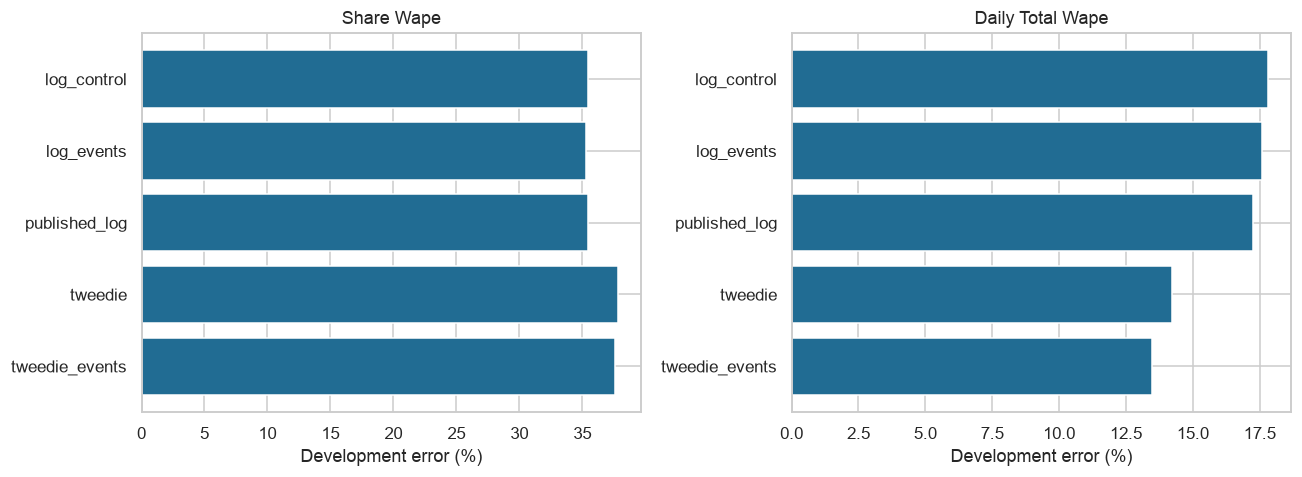

In [7]:
tweedie_annual=read(W,'annual_metrics.csv')
tweedie_development=read(W,'development_metrics.csv')
for row in tweedie_development.itertuples():
    actual=tweedie_annual.query('model == @row.model and segment == @row.segment and year in @DEV')
    for metric in ['log_rmse','share_wape','daily_total_wape','share_bias']:
        np.testing.assert_allclose(getattr(row,metric),actual[metric].mean(),atol=1e-12)
display(tweedie_development.query("segment == 'all'").set_index('model')[['log_rmse','share_wape','daily_total_wape','share_bias']])
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
all_models=tweedie_development.query("segment == 'all'").set_index('model')
for ax,metric in zip(axes,['share_wape','daily_total_wape']):
    ax.barh(all_models.index,100*all_models[metric],color='#216c93')
    ax.set(title=metric.replace('_',' ').title(),xlabel='Development error (%)')
    ax.invert_yaxis()
plt.tight_layout();plt.show()

## Rebalance and calendar-event features

The four additions are a Russell annual reconstitution-close flag, a stock's mean log auction lift over up to six preceding events of the same type, the count of contributing historical lifts, and the stock's lagged size percentile on event dates.

Event types are disjoint, with Russell close taking precedence over other quarter-end and other month-end. Lift is the log departure from the stock's prior 20-row median, clipped to [−3, 3]. The current event's outcome is excluded from its history. Quarter-end here is a calendar boundary, distinct from an options-expiry flag already present among the base features.

The experiment reuses the project's recorded 2015–2025 Russell-close schedule. Full point-in-time index membership, additions, deletions and weight changes were unavailable. Historical response and stock size serve as proxies for event exposure. The source README links the original schedule references. [Source study and calendar references](../outputs/experiments/23_tweedie_and_rebalance/README.md)

In [8]:
tw.eligible_events(con,PANEL)
event_dates=sql("SELECT event_type,count(DISTINCT date) AS sessions,count(*) AS stock_days FROM events WHERE year(date) BETWEEN 2022 AND 2025 GROUP BY event_type ORDER BY event_type")
display(event_dates)
assert sql('SELECT count(*) AS violations FROM events WHERE last_event_date >= date').violations.iloc[0]==0
stocks=sql('SELECT permno FROM events GROUP BY permno ORDER BY count(*) DESC,permno LIMIT 16').permno.tolist()
stock_list=','.join(map(str,stocks));schedule=','.join(f"DATE '{date}'" for date in tw.RUSSELL_CLOSE)
raw=sql(f"""
    SELECT date,permno,auction_volume,median20_auction_volume,
           CASE WHEN date IN ({schedule}) THEN 'russell'
                WHEN is_last_trading_day_quarter THEN 'quarter_end' ELSE 'month_end' END AS event_type
    FROM read_parquet('{PANEL}') WHERE eligible_target AND permno IN ({stock_list})
      AND (is_last_trading_day_month OR is_last_trading_day_quarter OR date IN ({schedule}))
    ORDER BY permno,event_type,date
""")
raw['lift']=np.where(raw.median20_auction_volume>0,np.clip(np.log1p(raw.auction_volume)-np.log1p(raw.median20_auction_volume),-3,3),np.nan)
raw['independent_prior_lift']=raw.groupby(['permno','event_type']).lift.transform(lambda s:s.shift(1).rolling(6,min_periods=1).mean())
raw['independent_prior_count']=raw.groupby(['permno','event_type']).lift.transform(lambda s:s.shift(1).rolling(6,min_periods=0).count())
stored=sql(f'SELECT date,permno,prior_event_log_lift,prior_event_count FROM events WHERE permno IN ({stock_list})')
joined=raw.merge(stored,on=['date','permno'],validate='one_to_one')
np.testing.assert_allclose(joined.independent_prior_lift,joined.prior_event_log_lift,equal_nan=True,atol=1e-12)
np.testing.assert_array_equal(joined.independent_prior_count,joined.prior_event_count)
print(f'Independently checked {len(joined):,} prior-event feature rows for {len(stocks)} stocks.')
display(tweedie_development.query("segment in ['russell','quarter_end','month_end']").set_index(['segment','model'])[['sessions','log_rmse','share_wape','daily_total_wape','share_bias']])

,event_type,sessions,stock_days
0,month_end,32,40723
1,quarter_end,15,19023
2,russell,4,5088


Independently checked 2,256 prior-event feature rows for 16 stocks.


,,sessions,log_rmse,share_wape,daily_total_wape,share_bias
segment,model,,,,,
month_end,log_control,8.0000,0.6630,0.4769,0.3216,-0.2705
quarter_end,log_control,3.6667,0.5719,0.3677,0.2184,-0.1094
russell,log_control,1.0000,1.1813,0.6901,0.5701,-0.5701
month_end,log_events,8.0000,0.6424,0.4649,0.3037,-0.2417
quarter_end,log_events,3.6667,0.5399,0.3422,0.1936,-0.1542
russell,log_events,1.0000,1.0150,0.6636,0.4035,-0.4035
month_end,published_log,8.0000,0.6590,0.4702,0.3097,-0.2692
quarter_end,published_log,3.6667,0.5746,0.3661,0.2206,-0.1318
russell,published_log,1.0000,1.1266,0.6816,0.5058,-0.5058


## Verify the saved four-way forecasts

Every saved 2022–2025 forecast is aligned to the authoritative stock/date labels. We recompute all six reported segments for all five forecasts, including the published reference. The realized top 1% segment is a retrospective diagnostic; it is never an input or a model-selection subgroup.

In [9]:
verified_tweedie=[]
for year in YEARS:
    progress(f'Verifying saved Tweedie/event forecasts {year}')
    frame=con.execute('SELECT * FROM read_parquet(?) ORDER BY date,permno',[str(W/f'predictions_{year}.parquet')]).df()
    reference=con.execute('SELECT date,permno,auction_volume FROM read_parquet(?) ORDER BY date,permno',
        [str(RESULTS/f'eda/09_global_finalists/predictions/global_finalist_predictions_{year}.parquet')]).df()
    pd.testing.assert_frame_equal(frame[['date','permno','auction_volume']],reference,check_dtype=False)
    assert not frame.duplicated(['date','permno']).any()
    segments={'all':frame,'actual_top_1pct':frame.loc[frame.auction_volume.nlargest(int(np.ceil(.01*len(frame)))).index]}
    segments.update({name:frame.loc[frame.event_type.eq(name)] for name in tw.SEGMENTS[1:-1]})
    for model in ['published_log',*tw.MODELS]:
        assert np.isfinite(frame[model]).all() and frame[model].ge(0).all()
        for segment,subset in segments.items():
            result=tw.score(subset.auction_volume,subset[model],subset.date)
            recorded=tweedie_annual.query('year == @year and model == @model and segment == @segment').iloc[0]
            for metric,value in result.items():np.testing.assert_allclose(value,recorded[metric],rtol=1e-9,atol=1e-10)
            assert result['daily_total_wape']<=result['share_wape']+1e-12
            verified_tweedie.append({'year':year,'model':model,'segment':segment,**result})
verified_tweedie=pd.DataFrame(verified_tweedie)
verified_tweedie.to_csv(RUN/'verified_tweedie_annual_metrics.csv',index=False)
assert len(verified_tweedie)==120
print('All 120 saved model/year/segment scores match.')
intervals=read(W,'paired_development_intervals.csv')
for row in intervals.itertuples():
    np.testing.assert_allclose(row.delta,all_models.loc[row.model,row.metric]-all_models.loc[row.control,row.metric],atol=1e-12)
display(intervals)

2026-11-18T16:33:39.390701+00:00 Verifying saved Tweedie/event forecasts 2022


2026-11-18T16:33:39.586942+00:00 Verifying saved Tweedie/event forecasts 2023


2026-11-18T16:33:39.780714+00:00 Verifying saved Tweedie/event forecasts 2024


2026-11-18T16:33:39.966109+00:00 Verifying saved Tweedie/event forecasts 2025


All 120 saved model/year/segment scores match.


,model,control,metric,delta,lower_95,upper_95
0,log_events,log_control,log_rmse,-0.0031,-0.0060,-0.0010
1,log_events,log_control,share_wape,-0.0022,-0.0043,-0.0006
2,log_events,log_control,daily_total_wape,-0.0020,-0.0073,0.0028
3,log_events,log_control,share_bias,-0.0009,-0.0053,0.0034
4,tweedie,log_control,log_rmse,0.0551,0.0506,0.0599
5,tweedie,log_control,share_wape,0.0231,0.0198,0.0268
6,tweedie,log_control,daily_total_wape,-0.0358,-0.0432,-0.0271
7,tweedie,log_control,share_bias,0.1052,0.0979,0.1126
8,tweedie_events,log_control,log_rmse,0.0466,0.0417,0.0514
9,tweedie_events,log_control,share_wape,0.0210,0.0171,0.0247


The source uncertainty intervals resample paired **20-session circular blocks within each year**, 4,000 times, recomputing each annual metric and averaging 2022–2024. They preserve short runs of dates and keep all stocks on the sampled dates together. They condition on the fitted models and do not account for repeated research choices. The earlier spline/mixture intervals instead resample individual whole dates; their uncertainty estimates are not directly interchangeable.

The event-enhanced log model improves log RMSE by about 0.00314 versus its matched log control, with a paired interval below zero. Its stock WAPE also improves. Russell-date daily-total WAPE falls from about 57% to 40%, but that development result covers just three Russell dates. The much larger regular-date sample gives stronger evidence for overall accuracy than those three annual events alone.

Tweedie plus events improves daily-total WAPE to about 13.45%, versus 17.59% for log plus events, and reduces underprediction. Its stock WAPE rises to about 37.58% and log RMSE to about 0.518. It is a candidate for a distinct aggregate-volume objective, rather than a replacement under our stock-level log-RMSE criterion.

## Fresh 2022 worked experiment: log / Tweedie × base / event features

This cell executes the original chronology, sampling seeds, preprocessing, hyperparameters and validation criteria for one evaluation year. It tunes six configurations: one log configuration for each feature set and Tweedie powers 1.3 and 1.7 for each feature set. Early stopping chooses tree counts. Both Tweedie powers are ranked on the same validation deviance with index 1.5; log candidates use bounded share-log RMSE.

We save all four fitted boosters and the refit preprocessor in the new audit directory. The original script did not retain fitted weights. Cached reruns reuse these artifacts only when the recorded plan matches; the following cell reconstructs every new forecast from those saved weights. This is a fresh 2022 fit, not a claim that all four historical folds were refitted here.

In [10]:
FRESH=RUN/'fresh_tweedie_2022'
required=[FRESH/'predictions_2022.parquet',FRESH/'fit_2022.json',FRESH/'preprocessor_2022.json',FRESH/'validation_2022.csv',
          *[FRESH/f'{name}_2022.txt' for name in tw.MODELS]]
if all(path.is_file() for path in required):
    progress('Using complete fresh-2022 cache; all saved boosters will be reconstructed below')
else:
    original_out,original_fit,original_preprocess=tw.OUT,tw.fit_model,tw.fit_preprocessor
    final_names=iter(tw.MODELS)
    def audited_fit(year,power,threads,train,validation=None,evaluate=None,rounds=1000):
        booster=original_fit(year,power,threads,train,validation,evaluate,rounds)
        if validation is None:
            name=next(final_names);booster.save_model(str(FRESH/f'{name}_{year}.txt'))
            progress(f'Saved fresh {name}: {rounds} trees')
        return booster
    def audited_preprocess(frame,*types):
        result=original_preprocess(frame,*types)
        if len(frame)==300000:write_json(FRESH/'preprocessor_2022.json',result[1])
        return result
    try:
        tw.OUT=FRESH;tw.fit_model=audited_fit;tw.fit_preprocessor=audited_preprocess
        (FRESH/'predictions_2022.parquet').unlink(missing_ok=True)
        progress('Starting fresh 2022 tuning and refitting')
        tw.run_fold(2022,PANEL,4,None)
    finally:
        tw.OUT=original_out;tw.fit_model=original_fit;tw.fit_preprocessor=original_preprocess
    assert all(path.is_file() for path in required)
fresh_meta=json.loads((FRESH/'fit_2022.json').read_text())
source_meta=json.loads((W/'fit_2022.json').read_text())
assert fresh_meta['samples']==source_meta['samples']
display(pd.DataFrame(fresh_meta['samples']).T)
display(pd.read_csv(FRESH/'validation_2022.csv'))
display(pd.DataFrame(fresh_meta['selected']).T)

2026-11-18T16:33:40.158200+00:00 Using complete fresh-2022 cache; all saved boosters will be reconstructed below


,rows,first,last,keys_sha256
tune,180000,2016-01-04,2020-12-31,9ed16d7b8fdd73164471042e662bebc9cc7db6bd798746...
validation,100000,2021-01-04,2021-12-31,85c795d048c981f052161ee20bac6cd834ef68a162b88a...
refit,300000,2017-01-03,2021-12-31,ad310452cd5aeeb3c1392ab6853832f05c66fd77b06e4a...
test,328634,2022-01-03,2022-12-30,249366a3b3d5781245f50a9de94e0542e91e4fb06073d0...


,model,power,rounds,criterion,rows,sessions,log_rmse,share_wape,daily_total_wape,share_bias
0,log_control,NaN,1000,0.5820,100000,252,0.5820,0.4256,0.2200,-0.1860
1,log_events,NaN,998,0.5793,100000,252,0.5793,0.4244,0.2136,-0.1780
2,tweedie,1.3000,805,6.1893,100000,252,0.6713,0.4551,0.1918,-0.0625
3,tweedie,1.7000,618,6.1871,100000,252,0.6522,0.4495,0.1872,-0.0754
4,tweedie_events,1.3000,279,6.1834,100000,252,0.6766,0.4537,0.1869,-0.0650
5,tweedie_events,1.7000,525,6.1802,100000,252,0.6536,0.4506,0.1814,-0.0694


,model,power,rounds,criterion,rows,sessions,log_rmse,share_wape,daily_total_wape,share_bias
log_control,log_control,None,1000,0.5820,100000,252,0.5820,0.4256,0.2200,-0.1860
log_events,log_events,None,998,0.5793,100000,252,0.5793,0.4244,0.2136,-0.1780
tweedie,tweedie,1.7000,618,6.1871,100000,252,0.6522,0.4495,0.1872,-0.0754
tweedie_events,tweedie_events,1.7000,525,6.1802,100000,252,0.6536,0.4506,0.1814,-0.0694


In [11]:
progress('Reconstructing all fresh 2022 saved boosters')
prep=json.loads((FRESH/'preprocessor_2022.json').read_text())
types=[list(prep[key]) for key in ['continuous','boolean','categorical']]
features=json.loads((RESULTS/'eda/09_global_finalists/frozen_global_benchmark.json').read_text())['features']
fresh_test=tw.get_frame(con,PANEL,types,2022,2023)
matrices=tw.matrix(fresh_test,prep,types,features)
fresh_forecasts=con.execute('SELECT * FROM read_parquet(?) ORDER BY date,permno',[str(FRESH/'predictions_2022.parquet')]).df()
old_forecasts=con.execute('SELECT * FROM read_parquet(?) ORDER BY date,permno',[str(W/'predictions_2022.parquet')]).df()
pd.testing.assert_frame_equal(fresh_test[['date','permno','auction_volume']],fresh_forecasts[['date','permno','auction_volume']],check_dtype=False)
fresh_comparison=[]
for name in tw.MODELS:
    booster=lgb.Booster(model_file=str(FRESH/f'{name}_2022.txt'))
    selected=fresh_meta['selected'][name]
    rebuilt=tw.predict(booster,matrices[int(name.endswith('events'))],fresh_test,fresh_meta['fallback'],
        np.log1p(fresh_meta['share_bounds']),selected['power'])
    np.testing.assert_allclose(rebuilt,fresh_forecasts[name],rtol=1e-9,atol=1e-7)
    result=tw.score(fresh_test.auction_volume,rebuilt,fresh_test.date)
    source=tw.score(old_forecasts.auction_volume,old_forecasts[name],old_forecasts.date)
    fresh_comparison.append({'model':name,**result,'source_log_rmse':source['log_rmse'],
        'log_rmse_difference':result['log_rmse']-source['log_rmse'],
        'max_forecast_difference':float(np.max(np.abs(rebuilt-old_forecasts[name].to_numpy())))})
fresh_comparison=pd.DataFrame(fresh_comparison)
fresh_comparison.to_csv(RUN/'fresh_2022_comparison.csv',index=False)
display(fresh_comparison.set_index('model'))
print('All four fresh saved boosters reconstruct their forecasts; source sample fingerprints match.')
del fresh_test,matrices,fresh_forecasts,old_forecasts;gc.collect()

2026-11-18T16:33:40.166323+00:00 Reconstructing all fresh 2022 saved boosters


,rows,sessions,log_rmse,share_wape,daily_total_wape,share_bias,source_log_rmse,log_rmse_difference,max_forecast_difference
model,,,,,,,,,
log_control,328634,251,0.5106,0.3655,0.1768,-0.1545,0.5106,0.0000,0.0000
log_events,328634,251,0.5097,0.3648,0.1728,-0.1515,0.5097,0.0000,0.0000
tweedie,328634,251,0.5787,0.3932,0.1312,-0.0290,0.5787,0.0000,0.0000
tweedie_events,328634,251,0.5775,0.3930,0.1192,-0.0227,0.5775,0.0000,0.0000


All four fresh saved boosters reconstruct their forecasts; source sample fingerprints match.


18109

## Checkpoint 5 decision

The fresh 2022 run uses the same stock/date sample fingerprints and selects the original tree counts: 1,000 for log control, 998 for log plus events, 618 for Tweedie and 525 for Tweedie plus events. Both Tweedie candidates select power 1.7. Fresh forecast scores match the source to floating-point precision; the largest reconstructed share difference is about 1e−8 shares.

| Method | What the evidence supports | Decision for the daily stock forecast |
| --- | --- | --- |
| Additive splines | Smooth effects improve slightly on the source ridge reference, but are materially behind verified LightGBM; stock effects add little | Retain as an interpretable challenger; no replacement |
| Tail mixture, log mean | Detects elevated spike risk, but improves development log RMSE by only about 0.00090 | Falls short of the 0.002 practical improvement gate |
| Tail mixture, share mean | Helps high-volume cases and aggregate underprediction, while worsening overall log accuracy | No replacement under the current criterion |
| Log loss plus event features | Improves the matched log control; promising event signals, with sparse annual-event evidence | Candidate extension to test against the tuned champion |
| Tweedie plus event features | Better daily-total WAPE and aggregate bias; worse stock-level log RMSE and stock WAPE | Keep for an explicitly aggregate forecasting objective |

The **tuned 61-feature LightGBM remains the daily champion** from the earlier checkpoints. This notebook's verified 58-feature reference and matched loss/event controls answer specific historical comparisons. They do not establish incremental gains over the tuned champion. A fair champion-extension test must hold its folds, training sample and tuning budget constant.

The original spline/mixture tables contain slightly inconsistent ridge-reference scores, documented above against authoritative saved ridge forecasts. Challenger forecasts and the shared LightGBM reference are independently verified. We preserve that distinction when interpreting conclusions.

We stop here for Checkpoint 5 review. Notebook 09 will consolidate the daily results after approval; notebook 10 will cover the intraday study, followed by notebook 11's dynamic correction and Kalman exploration.

In [12]:
print('2025 confirmation: reconstructed spline/tail/reference forecasts')
display(restored_metrics[restored_metrics.year.eq(2025)].set_index('candidate')[['rmse_log','wape','aggregate_bias']].rename(index=LABELS))
print('2025 confirmation: saved loss/event comparison')
display(verified_tweedie.query("year == 2025 and segment == 'all'").set_index('model')[['log_rmse','share_wape','daily_total_wape','share_bias']])
verification={'checkpoint':5,'plan_hash':PLAN_HASH,'reconstruction_years':YEARS,
    'spline_tail_reference_score_rows':len(restored_metrics),'tweedie_segment_score_rows':len(verified_tweedie),
    'fresh_saved_boosters':len(fresh_comparison),'independent_event_history_rows':len(joined),
    'fresh_sample_fingerprints_match':fresh_meta['samples']==source_meta['samples'],
    'completed_utc':datetime.now(timezone.utc).isoformat()}
write_json(RUN/'verification.json',verification)
display(pd.Series(verification,name='verified').to_frame())
con.close();work.cleanup()

2025 confirmation: reconstructed spline/tail/reference forecasts


,rmse_log,wape,aggregate_bias
candidate,,,
Pooled spline,0.4455,0.3426,-0.1011
Spline + stock effect,0.4455,0.3425,-0.1000
"Tail mixture, log mean",0.4289,0.3273,-0.1041
"Tail mixture, share mean",0.4319,0.3317,-0.0710
Verified 58-feature LightGBM,0.4306,0.3294,-0.0890


2025 confirmation: saved loss/event comparison


,log_rmse,share_wape,daily_total_wape,share_bias
model,,,,
published_log,0.4306,0.3294,0.1225,-0.0890
log_control,0.4322,0.3318,0.1255,-0.0800
log_events,0.4286,0.3292,0.1235,-0.0872
tweedie,0.4596,0.3572,0.1104,0.0050
tweedie_events,0.4554,0.3554,0.1063,0.0004


,verified
checkpoint,5
plan_hash,850ad50535832d0dd621783f95caa612a05d3d01f87fcc...
reconstruction_years,"[2022, 2023, 2024, 2025]"
spline_tail_reference_score_rows,20
tweedie_segment_score_rows,120
fresh_saved_boosters,4
independent_event_history_rows,2256
fresh_sample_fingerprints_match,True
completed_utc,2026-11-18T16:33:49.012718+00:00


## Source map

- [Spline experiment](../notebooks/run_spline_residual_experiment.py) and [saved results](../outputs/experiments/21_spline_residual/README.md).
- [Tail-mixture experiment](../notebooks/run_tail_mixture_experiment.py) and [saved results](../outputs/experiments/22_tail_mixture/README.md).
- [Tweedie/event experiment](../notebooks/compare_daily_tweedie_and_rebalance.py) and [saved results](../outputs/experiments/23_tweedie_and_rebalance/README.md).
- [New audit and fresh-fit artifacts](../outputs/experiments/30_checkpoint5_master_audit/).

Reconstruction checks validate saved model application and reported scoring. The worked fresh fit checks the original training procedure for 2022. Historical uncertainty tables are explicitly labelled as source calculations; their point estimates are checked here.